# Lesson 2 : LangGraph Components

In [9]:
from dotenv import load_dotenv
_ = load_dotenv()

In [ ]:
from langgraph.graph import StateGraph, END
from typing import TypedDict, Annotated
import operator
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage
from langchain_openai import ChatOpenAI
from langchain_community.tools import DuckDuckGoSearchResults
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper
from ddgs.exceptions import DDGSException


In [47]:
wrapper = DuckDuckGoSearchAPIWrapper(region="us-en", max_results=4, backend="google")
tool = DuckDuckGoSearchResults(api_wrapper=wrapper)
print(type(tool))
print(tool.name)

<class 'langchain_community.tools.ddg_search.tool.DuckDuckGoSearchResults'>
duckduckgo_results_json


> If you are not familiar with python typing annotation, you can refer to the [python documents](https://docs.python.org/3/library/typing.html).

In [48]:
class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]

> Note: in `take_action` below, some logic was added to cover the case that the LLM returned a non-existent tool name. Even with function calling, LLMs can still occasionally hallucinate. Note that all that is done is instructing the LLM to try again! An advantage of an agentic organization.

In [49]:
class Agent:

    def __init__(self, model, tools, system=""):
        self.system = system
        graph = StateGraph(AgentState)
        graph.add_node("llm", self.call_openai)
        graph.add_node("action", self.take_action)
        graph.add_conditional_edges(
            "llm",
            self.exists_action,
            {True: "action", False: END}
        )
        graph.add_edge("action", "llm")
        graph.set_entry_point("llm")
        self.graph = graph.compile()
        self.tools = {t.name: t for t in tools}
        self.model = model.bind_tools(tools)

    def exists_action(self, state: AgentState):
        result = state['messages'][-1]
        return len(result.tool_calls) > 0

    def call_openai(self, state: AgentState):
        messages = state['messages']
        if self.system:
            messages = [SystemMessage(content=self.system)] + messages
        message = self.model.invoke(messages)
        return {'messages': [message]}

    def take_action(self, state: AgentState):
        tool_calls = state['messages'][-1].tool_calls
        results = []
        for t in tool_calls:
            print(f"Calling: {t}")
            if not t['name'] in self.tools:      # check for bad tool name from LLM
                print("\n ....bad tool name....")
                result = "bad tool name, retry"  # instruct LLM to retry if bad
            else:
                result = self.tools[t['name']].invoke(t['args'])
            results.append(ToolMessage(tool_call_id=t['id'], name=t['name'], content=str(result)))
        print("Back to the model!")
        return {'messages': results}

In [50]:
prompt = """You are a smart research assistant. Use the search engine to look up information. \
You are allowed to make multiple calls (either together or in sequence). \
Only look up information when you are sure of what you want. \
If you need to look up some information before asking a follow up question, you are allowed to do that!
"""

model = ChatOpenAI(model="gpt-4.1")  #reduce inference cost
abot = Agent(model, [tool], system=prompt)

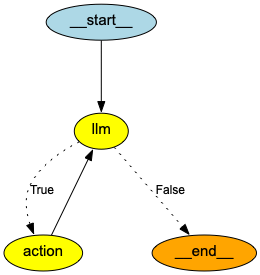

In [51]:
from IPython.display import Image

Image(abot.graph.get_graph().draw_png())

In [52]:
messages = [HumanMessage(content="What is the weather in sf?")]
result = abot.graph.invoke({"messages": messages})

Calling: {'name': 'duckduckgo_results_json', 'args': {'query': 'current weather in San Francisco'}, 'id': 'call_jtNTUB7MuXyanUVhAmOkptkN', 'type': 'tool_call'}
Back to the model!


In [53]:
result

{'messages': [HumanMessage(content='What is the weather in sf?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'call_jtNTUB7MuXyanUVhAmOkptkN', 'function': {'arguments': '{"query":"current weather in San Francisco"}', 'name': 'duckduckgo_results_json'}, 'type': 'function'}], 'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 22, 'prompt_tokens': 146, 'total_tokens': 168, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_672bcb1f11', 'id': 'chatcmpl-EnPvDVosXOahdrrRHX3t02TA3MLln', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='run--ca9a9b66-8fc7-4f98-a374-8150775d8055-0', tool_calls=[{'name': 'duckduckgo_results_json', 'args': {'query': 'current weather 

In [54]:
result['messages'][-1].content

'The current weather in San Francisco is partly cloudy with a low around 44°F and a high near 54°F. Winds are around 6 mph from the east. It’s partly sunny today and clouds are expected to increase later, with a low around 46°F tonight. For more up-to-date details and hourly forecasts, you can check local weather sources like The Weather Channel or The Weather Network.'

In [55]:
messages = [HumanMessage(content="What is the weather in SF and LA?")]
result = abot.graph.invoke({"messages": messages})

Calling: {'name': 'duckduckgo_results_json', 'args': {'query': 'current weather in San Francisco'}, 'id': 'call_ivcVkTBgEzv0Kj9A0U9HLYsK', 'type': 'tool_call'}
Calling: {'name': 'duckduckgo_results_json', 'args': {'query': 'current weather in Los Angeles'}, 'id': 'call_9rUhVbN9lx0TQlfmDeKDbask', 'type': 'tool_call'}
Back to the model!


In [56]:
result['messages'][-1].content

'The current weather in San Francisco is partly cloudy with a low around 44°F, and a high near 54°F today. Winds are from the east at around 6 mph.\n\nThe current weather in Los Angeles is sunny with a high near 69°F. Tonight will be mostly cloudy, with a low around 54°F. Winds are light, around 5 mph.\n\nFor up-to-date details, you can check:\n- San Francisco: [The Weather Channel for SF](https://weather.com/us/california/city/san-francisco/today)\n- Los Angeles: [The Weather Channel for LA](https://weather.com/us/california/city/los-angeles/today)'

In [58]:
# Note, the query was modified to produce more consistent results. 
# Results may vary per run and over time as search information and models change.

query = "Who won the super bowl in 2024? In what state is the winning team headquarters located? \
What is the GDP of that state? Answer each question." 
messages = [HumanMessage(content=query)]

model = ChatOpenAI(model="gpt-4.1")  # requires more advanced model
abot = Agent(model, [tool], system=prompt)
try:
    result = abot.graph.invoke({"messages": messages})
except DDGSException as e:
    result = ToolMessage(content=e.with_traceback())

Calling: {'name': 'duckduckgo_results_json', 'args': {'query': 'Who won the Super Bowl 2024?'}, 'id': 'call_YEa1PD8EIZmhAX4CYBEeq6QZ', 'type': 'tool_call'}
Calling: {'name': 'duckduckgo_results_json', 'args': {'query': "GDP of the state where the 2024 Super Bowl winning team's headquarters is located"}, 'id': 'call_zJQp5e6xcn1jAY9aSSGKhwGB', 'type': 'tool_call'}
Back to the model!


In [59]:
print(result['messages'][-1].content)

Here are the answers to your questions:

1. Who won the Super Bowl in 2024?
   - The Kansas City Chiefs won Super Bowl LVIII in 2024, defeating the San Francisco 49ers with a score of 25-22.

2. In what state is the winning team's headquarters located?
   - The Kansas City Chiefs' headquarters are located in the state of Missouri.

3. What is the GDP of that state?
   - Missouri's nominal GDP (as of recent data, 2024) can be found in official resources such as the U.S. Bureau of Economic Analysis; however, you can view Missouri's ranking and GDP value at sources like the BEA or statranker.org.

Would you like the exact GDP number for Missouri in 2024?
